# NB02: Structural MRI Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB02_Structural_MRI_Analysis.ipynb)


## Learning Objectives
- Load and visualize structural T1-weighted MRI images
- Understand brain anatomy in the context of glioma digital twins
- Load tumor segmentation masks and compute tumor volumes
- Compare pre- and post-operative anatomy
- Apply practical image processing for quantitative analysis

## Overview
Structural MRI provides the anatomical basis for digital twin models. This notebook demonstrates how to load, visualize, and analyze T1-weighted images, with special emphasis on tumor identification and volume measurement.

In [1]:
# Setup paths and imports
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from scipy import ndimage

# Environment setup (same as NB00)
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             '/content/glioma-brain-digital-twin'],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r /content/glioma-brain-digital-twin/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python /content/glioma-brain-digital-twin/data/download_data.py
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DATA_ROOT = REPO_ROOT / 'data' / 'BIDS_preop_postop'
sys.path.insert(0, str(REPO_ROOT))

print(f'Repository root: {REPO_ROOT}')
print(f'Data root:       {DATA_ROOT}')
print(f'Data exists:     {DATA_ROOT.exists()}')

# Set up visualization
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

Repository root: <REPO_ROOT>
Data root:       <REPO_ROOT>/data/BIDS_preop_postop
Data exists:     True


### 1. Brain Anatomy Overview for Applied Mathematicians

In [2]:
anatomy_text = '''STRUCTURAL BRAIN ANATOMY FOR MATHEMATICIANS
============================================

WHY BRAIN ANATOMY MATTERS FOR DIGITAL TWINS:
Mathematical models of gliomas depend on understanding:
1. Tissue microstructure and diffusivity tensors
2. Spatial relationships between tumor and white matter tracts
3. Biomechanical properties of gray vs white matter
4. Geometric constraints for growth simulations

KEY BRAIN COMPARTMENTS:

CEREBRAL CORTEX (Gray Matter)
- ~50 billion neurons per hemisphere
- Surface area: ~1500 cm^2 (convoluted)
- Thickness: 2-4 mm
- Site of cognitive processing
- Gliomas here affect specific functions

WHITE MATTER TRACTS
- Myelinated axons connecting neurons
- Major pathways act as barriers to tumor growth
- Measurable via diffusion tensor imaging (DTI)
- Critical for surgical planning
- Examples: corpus callosum, internal capsule

SUBCORTICAL STRUCTURES
- Thalamus: relay center for sensory/motor info
- Basal ganglia: movement control
- Cerebellum: coordination and balance
- Ventricles: cerebrospinal fluid (CSF) spaces

MAGNETIC RESONANCE IMAGING (MRI) PRINCIPLES:
- T1 image: Anatomical detail, fat/water contrast
- T2 image: Fluid contrast, edema detection
- FLAIR: Suppresses CSF, highlights pathology
- DTI: Water diffusion anisotropy

THE GLIOMA CONTEXT:
- Tumors preferentially grow along white matter
- Edema surrounds tumor core (appears bright on T2/FLAIR)
- Tumor core often has altered T1 relaxation
- Necrosis (dead tissue) appears hypointense on T1
'''
print(anatomy_text)

STRUCTURAL BRAIN ANATOMY FOR MATHEMATICIANS

WHY BRAIN ANATOMY MATTERS FOR DIGITAL TWINS:
Mathematical models of gliomas depend on understanding:
1. Tissue microstructure and diffusivity tensors
2. Spatial relationships between tumor and white matter tracts
3. Biomechanical properties of gray vs white matter
4. Geometric constraints for growth simulations

KEY BRAIN COMPARTMENTS:

CEREBRAL CORTEX (Gray Matter)
- ~50 billion neurons per hemisphere
- Surface area: ~1500 cm^2 (convoluted)
- Thickness: 2-4 mm
- Site of cognitive processing
- Gliomas here affect specific functions

WHITE MATTER TRACTS
- Myelinated axons connecting neurons
- Major pathways act as barriers to tumor growth
- Measurable via diffusion tensor imaging (DTI)
- Critical for surgical planning
- Examples: corpus callosum, internal capsule

SUBCORTICAL STRUCTURES
- Thalamus: relay center for sensory/motor info
- Basal ganglia: movement control
- Cerebellum: coordination and balance
- Ventricles: cerebrospinal fluid (CS

### 2. Load and Visualize T1-Weighted Images

In [3]:
# Load T1w images for inspection
t1w_files = sorted(DATA_ROOT.glob('sub-*/ses-*/anat/*T1w.nii.gz'))
print(f'Found {len(t1w_files)} T1w files')

if t1w_files:
    t1_path = t1w_files[0]
    print(f'\nLoading: {t1_path.name}')
    img_t1_orig = nib.load(str(t1_path))

    # Reorient to RAS+ canonical orientation
    img_t1 = nib.as_closest_canonical(img_t1_orig)
    data_t1 = img_t1.get_fdata()

    orig_ornt = nib.aff2axcodes(img_t1_orig.affine)
    canon_ornt = nib.aff2axcodes(img_t1.affine)
    print(f'Original orientation: {"".join(orig_ornt)}  →  Canonical: {"".join(canon_ornt)}')
    print(f'Shape: {data_t1.shape}')
    print(f'Data range: [{data_t1.min():.1f}, {data_t1.max():.1f}]')
    print(f'Mean intensity: {data_t1.mean():.1f}')
    print(f'Std intensity: {data_t1.std():.1f}')
    print(f'Voxel sizes (mm): {img_t1.header.get_zooms()[:3]}')
    print(f'Affine transformation:\n{img_t1.affine}')
else:
    print('No T1w files found')

Found 2 T1w files

Loading: sub-PAT16_ses-postop_T1w.nii.gz
Original orientation: RAS  →  Canonical: RAS
Shape: (160, 256, 256)
Data range: [0.0, 1118.0]
Mean intensity: 89.9
Std intensity: 134.9
Voxel sizes (mm): (1.0000061, 1.0, 1.0)
Affine transformation:
[[ 1.00000000e+00  0.00000000e+00 -3.47893895e-03 -7.49530945e+01]
 [ 0.00000000e+00  1.00000000e+00  0.00000000e+00 -1.11718048e+02]
 [ 3.47896013e-03  0.00000000e+00  9.99993920e-01 -1.30906250e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


### 3. Display Orthogonal Slices

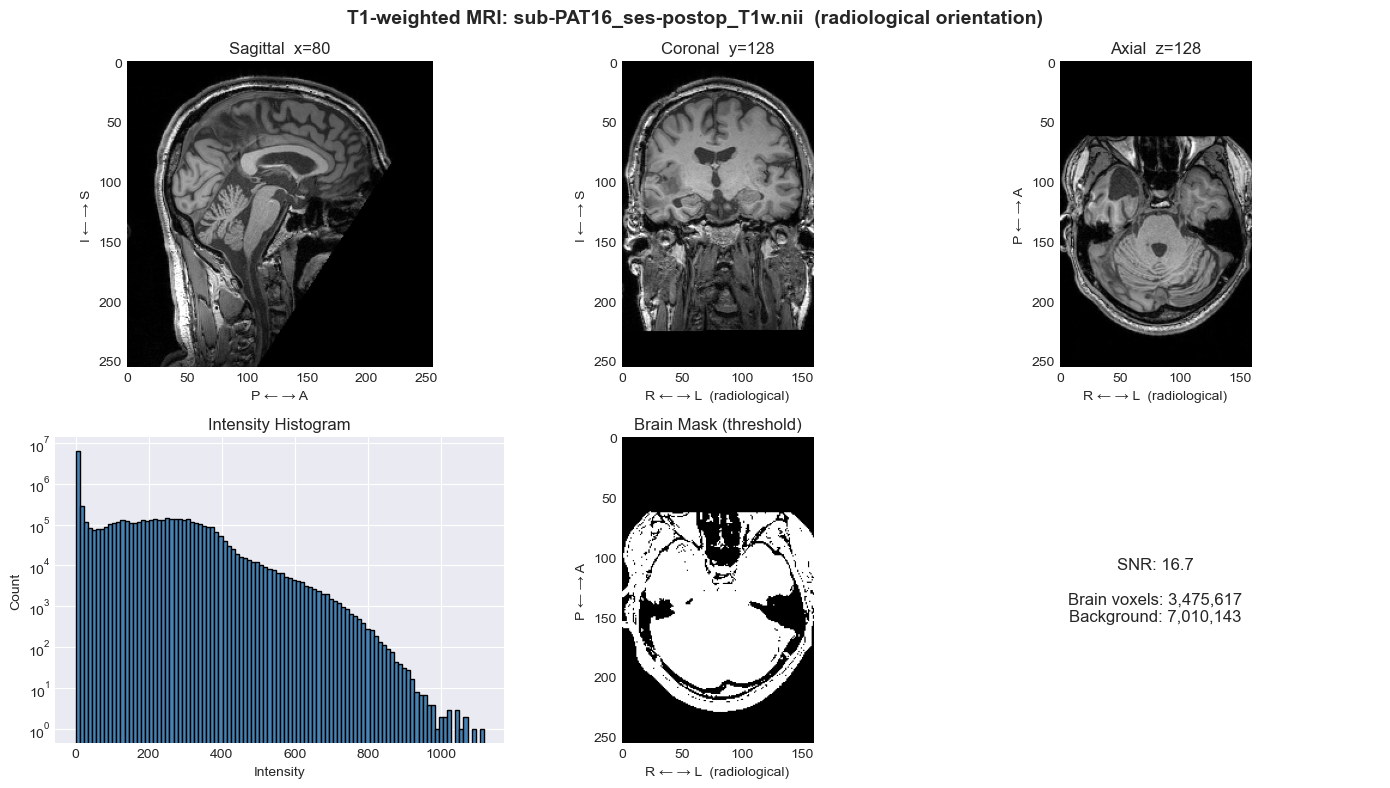

In [4]:
# Display brain slices in three orthogonal planes (RAS radiological convention)
# After as_closest_canonical(), array axes are: 0=R→L, 1=A→P, 2=I→S (RAS+).
# Radiological convention: patient's right on the viewer's left.

if t1w_files:
    vR, vA, vS = img_t1.header.get_zooms()[:3]

    # Robust intensity windowing: use percentiles of non-zero voxels
    nz = data_t1[data_t1 > 0]
    vmin_t1, vmax_t1 = np.percentile(nz, [1, 99.5])

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    fig.suptitle(f'T1-weighted MRI: {t1_path.stem}  (radiological orientation)',
                 fontsize=14, fontweight='bold')

    x_mid = data_t1.shape[0] // 2
    y_mid = data_t1.shape[1] // 2
    z_mid = data_t1.shape[2] // 2

    # Sagittal: after rot90 rows=S cols=A  →  aspect = vS/vA
    axes[0, 0].imshow(np.rot90(data_t1[x_mid, :, :]), cmap='gray', aspect=vS / vA,
                      vmin=vmin_t1, vmax=vmax_t1)
    axes[0, 0].set_title(f'Sagittal  x={x_mid}')
    axes[0, 0].set_xlabel('P ← → A')
    axes[0, 0].set_ylabel('I ← → S')
    axes[0, 0].grid(False)

    # Coronal: after rot90 rows=S cols=R (flipped)  →  aspect = vS/vR
    axes[0, 1].imshow(np.rot90(data_t1[:, y_mid, :])[:, ::-1], cmap='gray', aspect=vS / vR,
                      vmin=vmin_t1, vmax=vmax_t1)
    axes[0, 1].set_title(f'Coronal  y={y_mid}')
    axes[0, 1].set_xlabel('R ← → L  (radiological)')
    axes[0, 1].set_ylabel('I ← → S')
    axes[0, 1].grid(False)

    # Axial: after rot90 rows=A cols=R (flipped)  →  aspect = vA/vR
    axes[0, 2].imshow(np.rot90(data_t1[:, :, z_mid])[:, ::-1], cmap='gray', aspect=vA / vR,
                      vmin=vmin_t1, vmax=vmax_t1)
    axes[0, 2].set_title(f'Axial  z={z_mid}')
    axes[0, 2].set_xlabel('R ← → L  (radiological)')
    axes[0, 2].set_ylabel('P ← → A')
    axes[0, 2].grid(False)

    # Intensity histogram
    axes[1, 0].hist(data_t1.flatten(), bins=100, color='steelblue', edgecolor='black')
    axes[1, 0].set_title('Intensity Histogram')
    axes[1, 0].set_xlabel('Intensity')
    axes[1, 0].set_ylabel('Count')
    axes[1, 0].set_yscale('log')

    # Brain mask (simple threshold) — same axial orientation
    threshold = data_t1.mean()
    brain_mask = data_t1 > threshold
    axes[1, 1].imshow(np.rot90(brain_mask[:, :, z_mid])[:, ::-1], cmap='gray', aspect=vA / vR)
    axes[1, 1].set_title('Brain Mask (threshold)')
    axes[1, 1].set_xlabel('R ← → L  (radiological)')
    axes[1, 1].set_ylabel('P ← → A')
    axes[1, 1].grid(False)

    # SNR estimate
    brain_signal = data_t1[brain_mask]
    bg_signal = data_t1[~brain_mask]
    snr = (brain_signal.mean() - bg_signal.mean()) / bg_signal.std()
    axes[1, 2].text(0.5, 0.5,
                    f'SNR: {snr:.1f}\n\nBrain voxels: {brain_mask.sum():,}\n'
                    f'Background: {(~brain_mask).sum():,}',
                    ha='center', va='center', fontsize=12, transform=axes[1, 2].transAxes)
    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()

### 4. Register and Compare Pre- and Post-operative Images

── sub-PAT16 ──
  Pre-op:  sub-PAT16_ses-preop_T1w.nii.gz
  Post-op: sub-PAT16_ses-postop_T1w.nii.gz
  Registering post-op → pre-op (rigid, 6 DOF)...
  Registration complete.


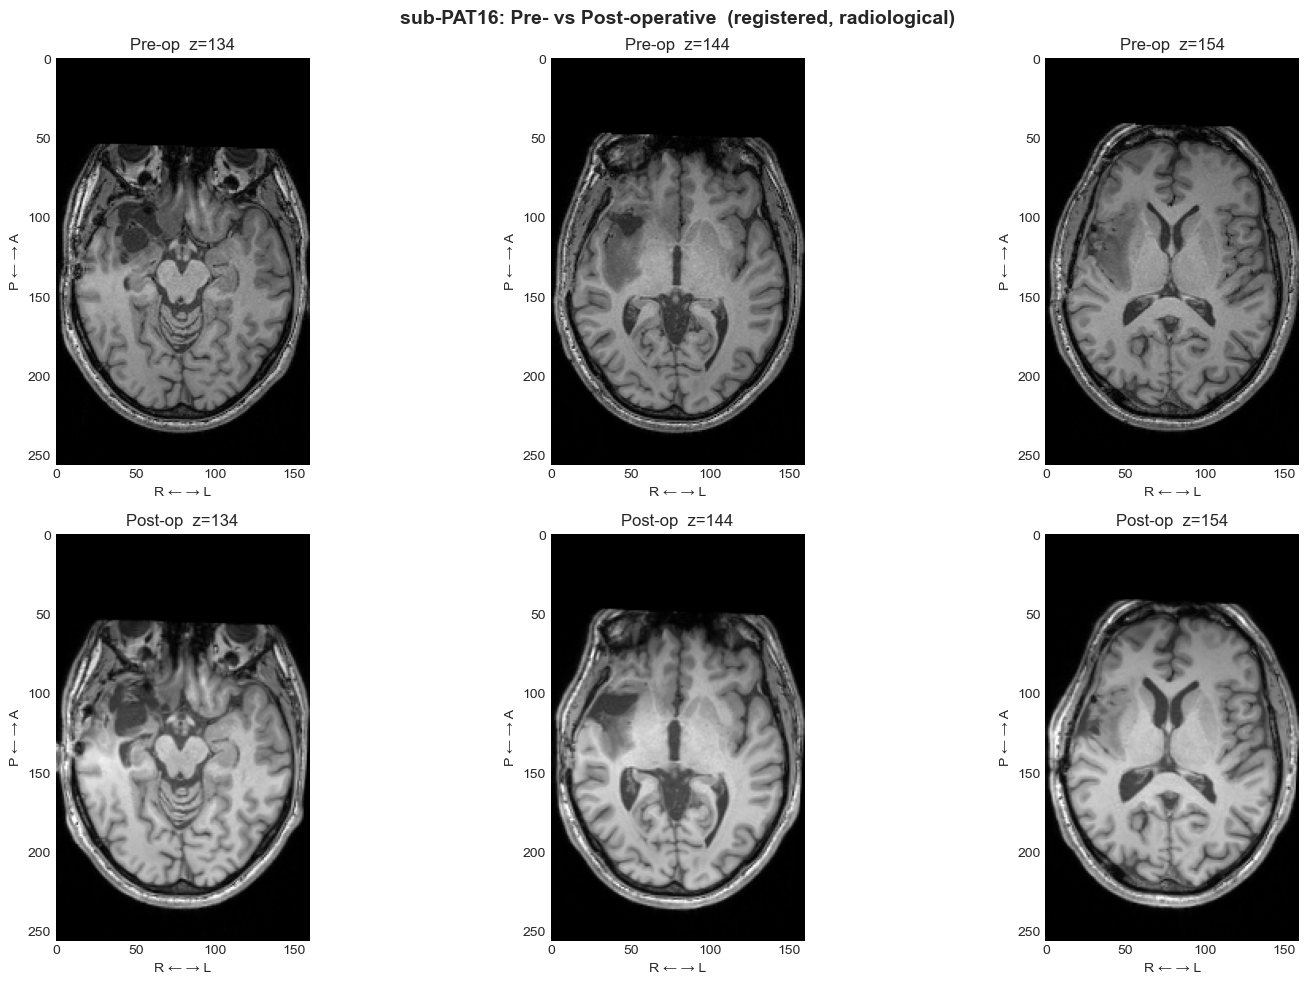

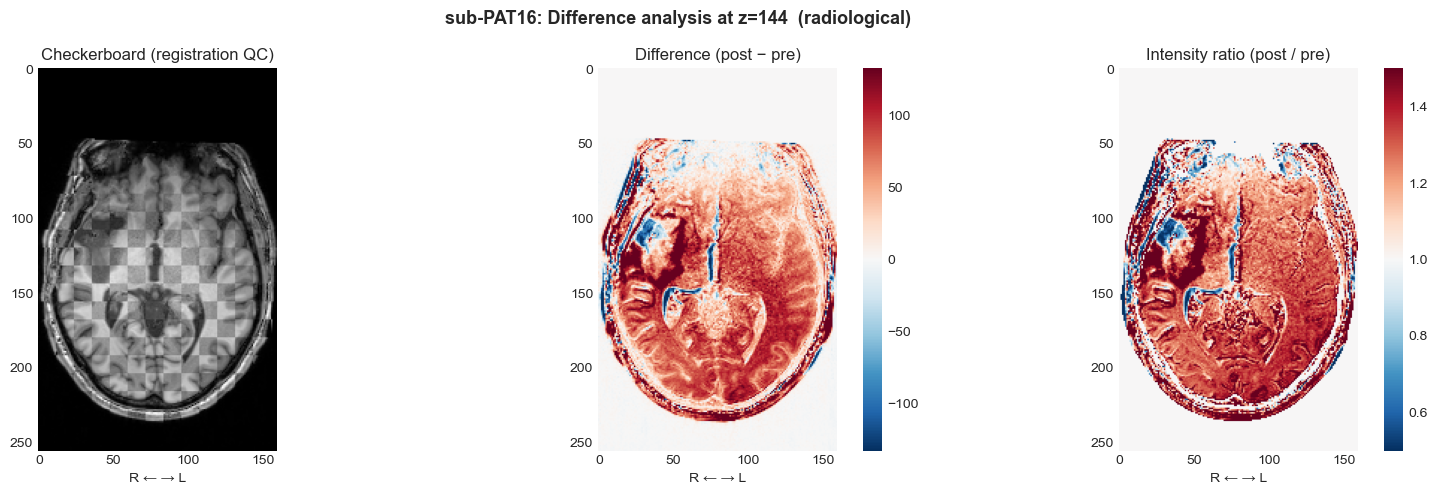

  Registration: rigid (6 DOF), mutual information, 3-level multi-scale
  Pre-op  volume: mean=65.5, std=100.2
  Post-op volume: mean=88.4, std=132.0
  Brain voxel difference: mean |Δ|=71.7, median=59.6, 95th pctile=184.6



In [5]:
%%time
from dipy.align.imaffine import AffineRegistration, MutualInformationMetric, AffineMap
from dipy.align.transforms import RigidTransform3D

def compare_preop_postop(pre_file, post_file, z_slices, diff_z_idx=None):
    """Register post-op to pre-op and visualize at selected axial slices."""
    subj = pre_file.parts[-4]
    print(f'── {subj} ──')
    print(f'  Pre-op:  {pre_file.name}')
    print(f'  Post-op: {post_file.name}')

    img_pre = nib.as_closest_canonical(nib.load(str(pre_file)))
    img_post = nib.as_closest_canonical(nib.load(str(post_file)))
    data_pre = img_pre.get_fdata()
    data_post_orig = img_post.get_fdata()

    print('  Registering post-op → pre-op (rigid, 6 DOF)...')
    metric = MutualInformationMetric(nbins=32, sampling_proportion=None)
    affreg = AffineRegistration(
        metric=metric, level_iters=[10000, 1000, 100],
        sigmas=[3.0, 1.0, 0.0], factors=[4, 2, 1], verbosity=0,
    )
    rigid = affreg.optimize(
        data_pre, data_post_orig, RigidTransform3D(), None,
        static_grid2world=img_pre.affine, moving_grid2world=img_post.affine,
    )
    data_post = rigid.transform(data_post_orig)
    print(f'  Registration complete.')

    vR, vA, vS = img_pre.header.get_zooms()[:3]
    nz_both = np.concatenate([data_pre[data_pre > 0], data_post[data_post > 0]])
    vmin_cmp, vmax_cmp = np.percentile(nz_both, [1, 99.5])

    # ── Pre-op (top) vs Post-op (bottom) at three axial levels ──
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    fig.suptitle(f'{subj}: Pre- vs Post-operative  (registered, radiological)',
                 fontsize=14, fontweight='bold')

    for col, z_idx in enumerate(z_slices):
        sl_pre = np.rot90(data_pre[:, :, z_idx])[:, ::-1]
        sl_post = np.rot90(data_post[:, :, z_idx])[:, ::-1]

        axes[0, col].imshow(sl_pre, cmap='gray', aspect=vA / vR,
                            vmin=vmin_cmp, vmax=vmax_cmp)
        axes[0, col].set_title(f'Pre-op  z={z_idx}')
        axes[0, col].set_xlabel('R ← → L')
        axes[0, col].set_ylabel('P ← → A')
        axes[0, col].grid(False)

        axes[1, col].imshow(sl_post, cmap='gray', aspect=vA / vR,
                            vmin=vmin_cmp, vmax=vmax_cmp)
        axes[1, col].set_title(f'Post-op  z={z_idx}')
        axes[1, col].set_xlabel('R ← → L')
        axes[1, col].set_ylabel('P ← → A')
        axes[1, col].grid(False)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # ── Difference analysis at the middle slice ──
    z_diff = diff_z_idx if diff_z_idx is not None else z_slices[1]
    ax_pre = np.rot90(data_pre[:, :, z_diff])[:, ::-1]
    ax_post = np.rot90(data_post[:, :, z_diff])[:, ::-1]

    fig2, axes2 = plt.subplots(1, 3, figsize=(16, 5))
    fig2.suptitle(f'{subj}: Difference analysis at z={z_diff}  (radiological)',
                  fontsize=13, fontweight='bold')

    checker_size = 12
    rows, cols = ax_pre.shape
    checker = np.zeros_like(ax_pre)
    for i in range(rows):
        for j in range(cols):
            if ((i // checker_size) + (j // checker_size)) % 2 == 0:
                checker[i, j] = ax_pre[i, j]
            else:
                checker[i, j] = ax_post[i, j]
    axes2[0].imshow(checker, cmap='gray', aspect=vA / vR,
                    vmin=vmin_cmp, vmax=vmax_cmp)
    axes2[0].set_title('Checkerboard (registration QC)')
    axes2[0].set_xlabel('R ← → L')
    axes2[0].grid(False)

    diff = ax_post.astype(float) - ax_pre.astype(float)
    vmax = np.percentile(np.abs(diff[diff != 0]), 95) if np.any(diff != 0) else 1
    im = axes2[1].imshow(diff, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect=vA / vR)
    axes2[1].set_title('Difference (post − pre)')
    axes2[1].set_xlabel('R ← → L')
    plt.colorbar(im, ax=axes2[1])
    axes2[1].grid(False)

    eps = 1e-6
    ratio = np.where(ax_pre > 50, ax_post / (ax_pre + eps), 1.0)
    im2 = axes2[2].imshow(ratio, cmap='RdBu_r', vmin=0.5, vmax=1.5, aspect=vA / vR)
    axes2[2].set_title('Intensity ratio (post / pre)')
    axes2[2].set_xlabel('R ← → L')
    plt.colorbar(im2, ax=axes2[2])
    axes2[2].grid(False)

    plt.tight_layout()
    plt.show()
    plt.close(fig2)

    # Statistics
    brain_mask_vol = data_pre > data_pre.mean() * 0.5
    diff_vol = np.abs(data_post.astype(float) - data_pre.astype(float))
    diff_brain_vol = diff_vol[brain_mask_vol]
    print(f'  Registration: rigid (6 DOF), mutual information, 3-level multi-scale')
    print(f'  Pre-op  volume: mean={data_pre.mean():.1f}, std={data_pre.std():.1f}')
    print(f'  Post-op volume: mean={data_post.mean():.1f}, std={data_post.std():.1f}')
    print(f'  Brain voxel difference: mean |Δ|={diff_brain_vol.mean():.1f}, '
          f'median={np.median(diff_brain_vol):.1f}, '
          f'95th pctile={np.percentile(diff_brain_vol, 95):.1f}')
    print()


# ── Run for both subjects ──
t1w_preop = sorted([f for f in t1w_files if 'ses-preop' in str(f)])
t1w_postop = sorted([f for f in t1w_files if 'ses-postop' in str(f)])

subject_slices = {
    'sub-PAT16': [134, 144, 154],
    'sub-PAT25': [130, 134, 138],
}

for pre_file in t1w_preop:
    subj = pre_file.parts[-4]
    match = [f for f in t1w_postop if subj in str(f)]
    if match:
        z_slices = subject_slices.get(subj, [128, 140, 152])
        compare_preop_postop(pre_file, match[0], z_slices)

### 5. Load and Analyze Tumor Masks

#### Tumor segmentation methodology

The tumor masks distributed with this dataset were created by
[Aerts et al. (2022)](https://doi.org/10.1038/s41597-022-01806-4)
using a **semi-automated pipeline** tailored to the tumor type:

**Glioma patients** (including PAT16 and PAT25):

1. **Initial segmentation** with the
   [Unified Segmentation with Lesion toolbox](https://doi.org/10.1016/j.neuroimage.2005.11.048)
   (C. Phillips), an SPM-based method that jointly segments tissue classes
   while accounting for a focal lesion.
2. **Manual refinement** by the lead researcher (H. Aerts) — described as
   "delineated in a semiautomated and manual way."
3. **Gaussian smoothing** (σ = 3 mm) of the binary mask, producing a
   **probabilistic map** with continuous values in [0, 1]. The smooth
   boundary was designed to gradually reduce the fiber orientation
   distribution (FOD) amplitude threshold during
   [3-tissue CSD tractography](https://doi.org/10.1101/629873),
   avoiding a hard cutoff at the tumor edge.

**Meningioma patients** (not in our subset) were handled differently:
FreeSurfer's `recon-all` automatically excluded the extra-axial mass in
most cases; manual edits were needed for two patients with very large
lesions.

**Spaces provided:**

| File suffix | Coordinate space | Use case |
|-------------|-----------------|----------|
| `*_space_T1_label-tumor` | Native T1w | Overlay on subject anatomy, FE mesh definition |
| `*_space_MNI_label-tumor` | MNI152 | Group-level overlap maps, atlas-based analysis |

**Interpreting the probability values:**

Because of the Gaussian smoothing, thresholding at `> 0` captures a large
penumbra around the tumor (e.g., ~530 cm³ for PAT16). A threshold of
`p > 0.5` yields the **core tumor volume** (≈ 45 cm³ for PAT16, ≈ 17 cm³
for PAT25). The full probability gradient is valuable for soft weighting
in tractography and biomechanical models.

**References:**

- Aerts, H. et al. (2022). *Pre- and post-surgery brain tumor multimodal
  MRI data optimized for large scale computational modelling.*
  Scientific Data **9**, 676.
  [doi:10.1038/s41597-022-01806-4](https://doi.org/10.1038/s41597-022-01806-4)
- Aerts, H. et al. (2018). *Modeling brain dynamics in brain tumor
  patients using The Virtual Brain.* eNeuro **5**.
  [doi:10.1523/ENEURO.0083-18.2018](https://doi.org/10.1523/ENEURO.0083-18.2018)
- Aerts, H., Dhollander, T. & Marinazzo, D. (2019). *Evaluating the
  performance of 3-tissue CSD pipelines for within-tumor tractography.*
  bioRxiv 629873.
  [doi:10.1101/629873](https://doi.org/10.1101/629873)
- Phillips, C. & Pernet, C. (2017). *Unified Segmentation with Lesion.*
  [SPM toolbox](https://doi.org/10.1016/j.neuroimage.2005.11.048)

In [6]:
# Look for tumor segmentation masks in derivatives
DERIV_ROOT = DATA_ROOT / 'derivatives'
mask_files = sorted(DERIV_ROOT.rglob('*tumor*.nii.gz')) if DERIV_ROOT.exists() else []

print(f'Found {len(mask_files)} tumor mask files:\n')

if mask_files:
    import pandas as pd

    rows = []
    for mf in mask_files:
        img = nib.as_closest_canonical(nib.load(str(mf)))
        dm = img.get_fdata() > 0.5
        vox_sizes = img.header.get_zooms()[:3]
        vox_vol = np.prod(vox_sizes)
        vol_mm3 = dm.sum() * vox_vol
        vol_cm3 = vol_mm3 / 1000

        subj = [p for p in mf.parts if p.startswith('sub-')][0]
        space = 'MNI' if 'MNI' in mf.name else 'T1w'

        rows.append({
            'Subject': subj, 'Space': space,
            'Shape': str(dm.shape),
            'Voxel (mm)': f'{vox_sizes[0]:.2f} × {vox_sizes[1]:.2f} × {vox_sizes[2]:.2f}',
            'Voxel vol (mm³)': f'{vox_vol:.2f}',
            'Mask voxels': int(dm.sum()),
            'Volume (cm³)': f'{vol_cm3:.2f}',
        })
        print(f'{mf.relative_to(DATA_ROOT)}')
        print(f'  Shape: {dm.shape}  |  Voxels: {dm.sum():,}  |  '
              f'Voxel vol: {vox_vol:.2f} mm³  |  Tumor vol: {vol_cm3:.2f} cm³')

    print()
    df_masks = pd.DataFrame(rows)
    display(df_masks)

    # Keep the T1-space mask of the first subject for the overlay cell below
    subj_label = t1_path.parts[-3] if t1w_files else ''
    t1_masks = [f for f in mask_files if 'T1' in f.name and subj_label in str(f)]
    mask_path = t1_masks[0] if t1_masks else mask_files[0]
    img_mask = nib.as_closest_canonical(nib.load(str(mask_path)))
    data_mask_prob = img_mask.get_fdata()
    data_mask = data_mask_prob > 0.5
    print(f'\nMask for overlay: {mask_path.name}')
    print(f'  Probabilistic map range: [{data_mask_prob.min():.3f}, {data_mask_prob.max():.3f}]')
    print(f'  Threshold > 0.5: {data_mask.sum():,} voxels')
else:
    print('No tumor masks found in expected locations')
    data_mask = None

Found 4 tumor mask files:

derivatives/tumor_masks/sub-PAT16/anat/sub-PAT16_space_MNI_label-tumor.nii.gz
  Shape: (121, 145, 121)  |  Voxels: 15,702  |  Voxel vol: 3.38 mm³  |  Tumor vol: 52.99 cm³
derivatives/tumor_masks/sub-PAT16/anat/sub-PAT16_space_MNI_label-tumor_binary.nii.gz
  Shape: (121, 145, 121)  |  Voxels: 15,703  |  Voxel vol: 3.38 mm³  |  Tumor vol: 53.00 cm³
derivatives/tumor_masks/sub-PAT16/anat/sub-PAT16_space_T1_label-tumor.nii.gz
  Shape: (160, 256, 256)  |  Voxels: 45,400  |  Voxel vol: 1.00 mm³  |  Tumor vol: 45.40 cm³
derivatives/tumor_masks/sub-PAT16/anat/sub-PAT16_space_T1_label-tumor_binary.nii.gz
  Shape: (160, 256, 256)  |  Voxels: 45,431  |  Voxel vol: 1.00 mm³  |  Tumor vol: 45.43 cm³



,Subject,Space,Shape,Voxel (mm),Voxel vol (mm³),Mask voxels,Volume (cm³)
0,sub-PAT16,MNI,"(121, 145, 121)",1.50 × 1.50 × 1.50,3.38,15702,52.99
1,sub-PAT16,MNI,"(121, 145, 121)",1.50 × 1.50 × 1.50,3.38,15703,53.00
2,sub-PAT16,T1w,"(160, 256, 256)",1.00 × 1.00 × 1.00,1.00,45400,45.40
3,sub-PAT16,T1w,"(160, 256, 256)",1.00 × 1.00 × 1.00,1.00,45431,45.43



Mask for overlay: sub-PAT16_space_MNI_label-tumor.nii.gz
  Probabilistic map range: [0.000, 1.081]
  Threshold > 0.5: 15,702 voxels


### 6. Visualize Tumor Overlay

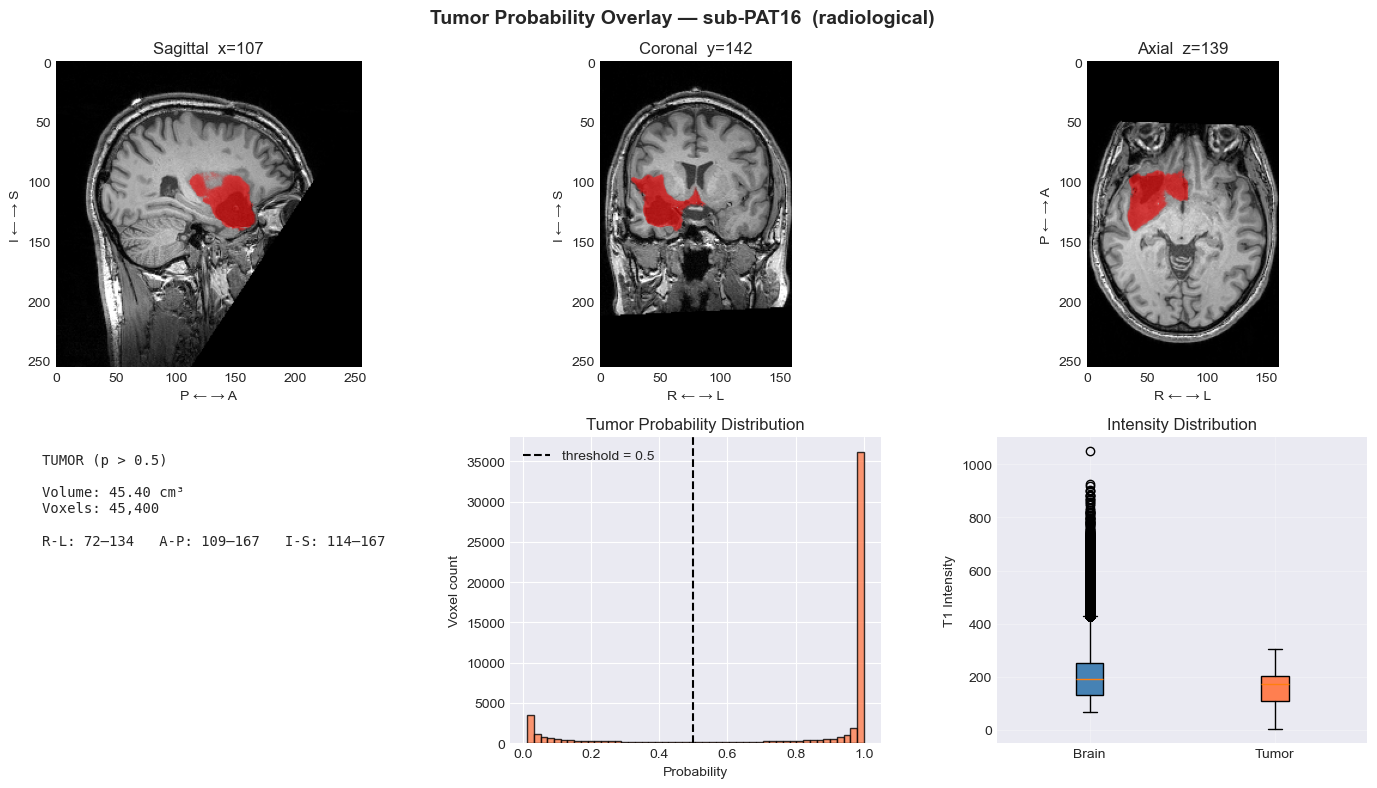

sub-PAT16: tumor volume = 45.40 cm³  (45,400 voxels at p > 0.5)



In [7]:
from matplotlib.colors import ListedColormap
from nibabel.processing import resample_from_to

red_cmap = ListedColormap([[1, 0, 0, a] for a in np.linspace(0, 0.6, 256)])

def overlay_tumor(t1w_path, mask_path, subj_label):
    """Overlay tumor probability map on pre-op T1w for one subject."""
    img_t1_s = nib.as_closest_canonical(nib.load(str(t1w_path)))
    img_mk_s = nib.as_closest_canonical(nib.load(str(mask_path)))

    # Resample mask to T1w grid if needed
    if img_mk_s.shape != img_t1_s.shape:
        img_mk_s = resample_from_to(img_mk_s, img_t1_s, order=1)

    d_t1 = img_t1_s.get_fdata()
    d_prob = img_mk_s.get_fdata()
    d_bin = d_prob > 0.5

    # Centroid of thresholded mask
    coords = np.argwhere(d_bin)
    cx, cy, cz = coords.mean(axis=0).astype(int) if len(coords) else [s//2 for s in d_t1.shape]

    vR, vA, vS = img_t1_s.header.get_zooms()[:3]
    nz = d_t1[d_t1 > 0]
    vmin_t1, vmax_t1 = np.percentile(nz, [1, 99.5])

    voxel_vol = np.prod(img_t1_s.header.get_zooms()[:3])
    vol_cm3 = d_bin.sum() * voxel_vol / 1000

    slices_info = [
        ('Sagittal', 'x', cx, lambda d: np.rot90(d[cx, :, :]),           vS / vA, 'P ← → A', 'I ← → S'),
        ('Coronal',  'y', cy, lambda d: np.rot90(d[:, cy, :])[:, ::-1],  vS / vR, 'R ← → L', 'I ← → S'),
        ('Axial',    'z', cz, lambda d: np.rot90(d[:, :, cz])[:, ::-1],  vA / vR, 'R ← → L', 'P ← → A'),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    fig.suptitle(f'Tumor Probability Overlay — {subj_label}  (radiological)',
                 fontsize=14, fontweight='bold')

    for col, (name, ax_lbl, idx, slicer, aspect, xlabel, ylabel) in enumerate(slices_info):
        axes[0, col].imshow(slicer(d_t1), cmap='gray', aspect=aspect,
                            vmin=vmin_t1, vmax=vmax_t1)
        axes[0, col].imshow(slicer(d_prob), cmap=red_cmap, aspect=aspect,
                            vmin=0, vmax=1)
        axes[0, col].set_title(f'{name}  {ax_lbl}={idx}')
        axes[0, col].set_xlabel(xlabel)
        axes[0, col].set_ylabel(ylabel)
        axes[0, col].grid(False)

    # Statistics
    bbox = (f'R-L: {coords[:,0].min()}–{coords[:,0].max()}   '
            f'A-P: {coords[:,1].min()}–{coords[:,1].max()}   '
            f'I-S: {coords[:,2].min()}–{coords[:,2].max()}') if len(coords) else 'N/A'
    axes[1, 0].text(0.05, 0.95,
        f'TUMOR (p > 0.5)\n\nVolume: {vol_cm3:.2f} cm³\nVoxels: {d_bin.sum():,}\n\n{bbox}',
        transform=axes[1, 0].transAxes, fontfamily='monospace', fontsize=10, verticalalignment='top')
    axes[1, 0].axis('off')

    # Probability histogram
    prob_vals = d_prob[d_prob > 0.01]
    axes[1, 1].hist(prob_vals, bins=50, color='coral', edgecolor='black', alpha=0.8)
    axes[1, 1].axvline(0.5, color='black', linestyle='--', label='threshold = 0.5')
    axes[1, 1].set_title('Tumor Probability Distribution')
    axes[1, 1].set_xlabel('Probability')
    axes[1, 1].set_ylabel('Voxel count')
    axes[1, 1].legend()

    # Intensity comparison
    brain_simple = d_t1 > d_t1.mean()
    bp = axes[1, 2].boxplot([d_t1[brain_simple & ~d_bin], d_t1[d_bin]],
                            tick_labels=['Brain', 'Tumor'], patch_artist=True)
    bp['boxes'][0].set_facecolor('steelblue')
    bp['boxes'][1].set_facecolor('coral')
    axes[1, 2].set_title('Intensity Distribution')
    axes[1, 2].set_ylabel('T1 Intensity')
    axes[1, 2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print(f'{subj_label}: tumor volume = {vol_cm3:.2f} cm³  ({d_bin.sum():,} voxels at p > 0.5)\n')


# ── Run for both subjects ──
t1w_preop = sorted([f for f in t1w_files if 'ses-preop' in str(f)])
MASK_ROOT = DATA_ROOT / 'derivatives' / 'tumor_masks'

for pre_file in t1w_preop:
    subj = pre_file.parts[-4]
    mask_candidates = sorted((MASK_ROOT / subj / 'anat').glob('*space_T1*tumor*'))
    if mask_candidates:
        overlay_tumor(pre_file, mask_candidates[0], subj)
    else:
        print(f'{subj}: no T1-space tumor mask found')

### 7. Summary and Key Insights

In [8]:
summary = '''STRUCTURAL MRI ANALYSIS SUMMARY
===============================

KEY CONCEPTS:
1. T1-weighted images provide anatomical detail
2. Voxel size affects volume calculations
3. Tumor segmentation enables quantitative analysis
4. Pre/post comparison reveals surgical effects

MATHEMATICAL RELEVANCE:
- Voxel intensities are continuous random variables
- Affine transformations map image to stereotactic space
- Binary masks define spatial domains for PDEs
- Tumor volume is basis for growth models

NEXT STEPS:
- NB03: Analyze diffusion properties (DTI)
- Model tumor growth using measured anatomies
- Validate predictions against postop imaging
'''
print(summary)

STRUCTURAL MRI ANALYSIS SUMMARY

KEY CONCEPTS:
1. T1-weighted images provide anatomical detail
2. Voxel size affects volume calculations
3. Tumor segmentation enables quantitative analysis
4. Pre/post comparison reveals surgical effects

MATHEMATICAL RELEVANCE:
- Voxel intensities are continuous random variables
- Affine transformations map image to stereotactic space
- Binary masks define spatial domains for PDEs
- Tumor volume is basis for growth models

NEXT STEPS:
- NB03: Analyze diffusion properties (DTI)
- Model tumor growth using measured anatomies
- Validate predictions against postop imaging

